In [ ]:
set up importing all libraries

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict,
                                     RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             fbeta_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# ---- Speed settings (the dataset is large) ----
SAMPLE_N = 60000       # rows used for model comparison and tuning (final model uses ALL training rows)
N_FOLDS = 3            # folds used for comparison / tuning
N_ITER = 8             # random parameter combinations tried in tuning
MAX_FLAG_RATE = 0.30   # business limit: flag at most 30% of customers for the campaign
BETA = 2               # recall counts BETA times as much as precision when choosing the threshold

In [ ]:
2.load the data 

In [5]:
USE_DATABASE = True            # set to False to read the saved CSV instead
CSV_BACKUP = "telecom_churn_data.csv"

DB_HOST = "18.136.157.135"
DB_PORT = 3306
DB_NAME = "project_telecom"
DB_TABLE = "telecom_churn_data"

if USE_DATABASE:
    from getpass import getpass
    from sqlalchemy import create_engine
    from sqlalchemy.engine import URL

    db_user = input("DB username: ").strip()
    db_password = getpass("DB password: ").strip()
    url = URL.create("mysql+pymysql", username=db_user, password=db_password,
                     host=DB_HOST, port=DB_PORT, database=DB_NAME)
    engine = create_engine(url)
    df_raw = pd.read_sql(f"SELECT * FROM {DB_TABLE}", engine)
    df_raw.to_csv(CSV_BACKUP, index=False)
else:
    df_raw = pd.read_csv(CSV_BACKUP)

# Tidy column names (strip spaces, lower case, underscores) and check we have what we need
df_raw.columns = (df_raw.columns.str.strip().str.lower().str.replace(r"[\s\-]+", "_", regex=True))
expected = ["customer_id", "telecom_partner", "gender", "age", "state", "city", "pincode",
            "date_of_registration", "num_dependents", "estimated_salary",
            "calls_made", "sms_sent", "data_used", "churn"]
missing_cols = [c for c in expected if c not in df_raw.columns]
assert not missing_cols, f"These columns are missing: {missing_cols}. Found: {df_raw.columns.tolist()}"

df = df_raw.copy()
print("Shape:", df.shape)
df.head()

DB username:  dm_team3 
DB password:  ········


Shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [8]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (243553, 14)

Column names:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn']

First 5 rows:


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   customer_id           243553 non-null  int64
 1   telecom_partner       243553 non-null  str  
 2   gender                243553 non-null  str  
 3   age                   243553 non-null  int64
 4   state                 243553 non-null  str  
 5   city                  243553 non-null  str  
 6   pincode               243553 non-null  int64
 7   date_of_registration  243553 non-null  str  
 8   num_dependents        243553 non-null  int64
 9   estimated_salary      243553 non-null  int64
 10  calls_made            243553 non-null  int64
 11  sms_sent              243553 non-null  int64
 12  data_used             243553 non-null  int64
 13  churn                 243553 non-null  int64
dtypes: int64(9), str(5)
memory usage: 26.0 MB


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   customer_id           243553 non-null  int64
 1   telecom_partner       243553 non-null  str  
 2   gender                243553 non-null  str  
 3   age                   243553 non-null  int64
 4   state                 243553 non-null  str  
 5   city                  243553 non-null  str  
 6   pincode               243553 non-null  int64
 7   date_of_registration  243553 non-null  str  
 8   num_dependents        243553 non-null  int64
 9   estimated_salary      243553 non-null  int64
 10  calls_made            243553 non-null  int64
 11  sms_sent              243553 non-null  int64
 12  data_used             243553 non-null  int64
 13  churn                 243553 non-null  int64
dtypes: int64(9), str(5)
memory usage: 26.0 MB


In [ ]:
3.data understanding

In [9]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().any().any() else "None")
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer_id:", df["customer_id"].duplicated().sum())
print("\nUnique values per column:")
display(df.nunique().to_frame("unique_values"))
display(df.describe().T)

Missing values per column:
None

Duplicate rows: 0
Duplicate customer_id: 0

Unique values per column:


,unique_values
customer_id,243553
telecom_partner,4
gender,2
age,57
state,28
city,6
pincode,213442
date_of_registration,1220
num_dependents,5
estimated_salary,110032


,count,mean,std,min,25%,50%,75%,max
customer_id,243553.0,121777.000000,70307.839393,1.0,60889.0,121777.0,182665.0,243553.0
age,243553.0,46.077609,16.444029,18.0,32.0,46.0,60.0,74.0
pincode,243553.0,549501.270541,259808.860574,100006.0,324586.0,548112.0,774994.0,999987.0
num_dependents,243553.0,1.997500,1.414941,0.0,1.0,2.0,3.0,4.0
estimated_salary,243553.0,85021.137839,37508.963233,20000.0,52585.0,84990.0,117488.0,149999.0
calls_made,243553.0,49.010548,29.453556,-10.0,24.0,49.0,74.0,108.0
sms_sent,243553.0,23.945404,14.733575,-5.0,11.0,24.0,36.0,53.0
data_used,243553.0,4993.186025,2942.019547,-987.0,2490.0,4987.0,7493.0,10991.0
churn,243553.0,0.200478,0.400359,0.0,0.0,0.0,0.0,1.0


In [11]:
for col in ["telecom_partner", "gender", "state"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))


telecom_partner:
telecom_partner
Reliance Jio    61123
Airtel          60905
Vodafone        60802
BSNL            60723
Name: count, dtype: int64

gender:
gender
M    145977
F     97576
Name: count, dtype: int64

state:
state
Uttarakhand          8856
Karnataka            8845
Maharashtra          8820
Madhya Pradesh       8817
Arunachal Pradesh    8757
Jharkhand            8755
Rajasthan            8750
Uttar Pradesh        8742
Haryana              8740
Kerala               8725
Tamil Nadu           8718
Odisha               8712
Goa                  8694
Mizoram              8689
Telangana            8689
Name: count, dtype: int64


In [ ]:
4.data cleaning and quality check

In [12]:
# 4.1 Remove exact duplicate rows / duplicate customers (if any)
before = len(df)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="customer_id", keep="first")
print(f"Rows removed as duplicates: {before - len(df)}")

# 4.2 Parse the registration date
df["date_of_registration"] = pd.to_datetime(df["date_of_registration"], errors="coerce")
print("Unparseable registration dates:", df["date_of_registration"].isnull().sum())
print("Registration date range:", df["date_of_registration"].min(), "->", df["date_of_registration"].max())

# 4.3 Standardise text columns and the target
for col in ["telecom_partner", "gender", "state", "city"]:
    df[col] = df[col].astype("string").str.strip()

def to_binary(series):
    s = series.astype(str).str.strip().str.lower().str.rstrip(".")
    mapping = {"yes": 1, "no": 0, "true": 1, "false": 0,
               "1": 1, "0": 0, "1.0": 1, "0.0": 0}
    out = s.map(mapping)
    if out.isnull().any():
        raise ValueError(f"Unmapped values in {series.name}: {series[out.isnull()].unique()[:10]}")
    return out.astype(int)

df["churn"] = to_binary(df["churn"])

# 4.4 Look for impossible / suspicious values (reported, not deleted)
print("\nNegative values:",
      {c: int((df[c] < 0).sum()) for c in ["age", "num_dependents", "estimated_salary",
                                          "calls_made", "sms_sent", "data_used"]})
print("Age outside 18-100:", int(((df["age"] < 18) | (df["age"] > 100)).sum()))

# 4.5 Outlier overview (IQR rule) - reported only; tree models are robust to outliers
num_check = ["age", "estimated_salary", "calls_made", "sms_sent", "data_used"]
rows = []
for c in num_check:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    rows.append({"column": c, "outliers_%": ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).mean() * 100})
display(pd.DataFrame(rows).set_index("column").round(2))

Rows removed as duplicates: 0
Unparseable registration dates: 0
Registration date range: 2020-01-01 00:00:00 -> 2023-05-04 00:00:00

Negative values: {'age': 0, 'num_dependents': 0, 'estimated_salary': 0, 'calls_made': 6713, 'sms_sent': 7375, 'data_used': 6050}
Age outside 18-100: 0


,outliers_%
column,
age,0.0
estimated_salary,0.0
calls_made,0.0
sms_sent,0.0
data_used,0.0


In [ ]:
5.target variable -churn rate

Churn rate: 20.05%  (48,827 of 243,553 customers)


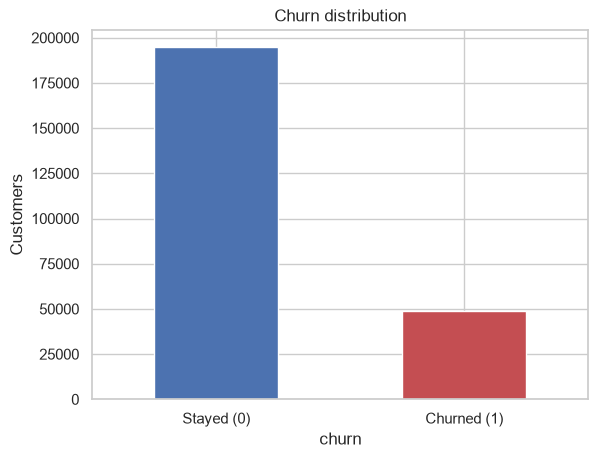

In [13]:
churn_rate = df["churn"].mean()
print(f"Churn rate: {churn_rate:.2%}  ({df['churn'].sum():,} of {len(df):,} customers)")

ax = df["churn"].value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Stayed (0)", "Churned (1)"], rotation=0)
ax.set_title("Churn distribution")
ax.set_ylabel("Customers")
plt.show()

In [ ]:
6.exploratory data analysis(EDA)

In [16]:
def churn_by(series, title, rotate=0, top=None):
    """Bar chart + table of churn rate for each group of `series`."""
    g = df.groupby(series, observed=True)["churn"].agg(["mean", "count"])
    g["mean"] *= 100
    g = g.rename(columns={"mean": "churn_%", "count": "customers"})
    if top:
        g = g.sort_values("churn_%", ascending=False).head(top)
    ax = g["churn_%"].plot(kind="bar", color="#4C72B0", figsize=(8, 3.6), rot=rotate)
    ax.axhline(churn_rate * 100, color="red", ls="--", label="overall")
    ax.set_title(title); ax.set_ylabel("Churn %"); ax.legend()
    plt.tight_layout(); plt.show()
    return g.round(2)

In [ ]:
6.1 categorical values

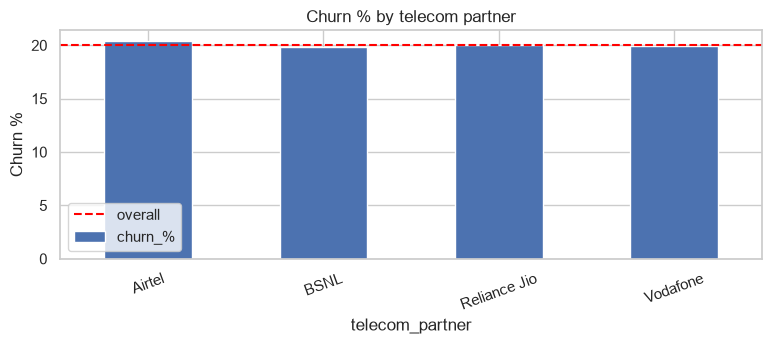

,churn_%,customers
telecom_partner,,
Airtel,20.37,60905
BSNL,19.86,60723
Reliance Jio,20.02,61123
Vodafone,19.95,60802


In [15]:
display(churn_by(df["telecom_partner"], "Churn % by telecom partner", rotate=20))

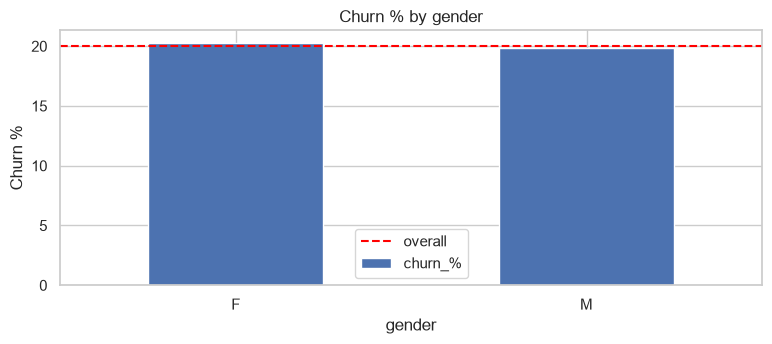

,churn_%,customers
gender,,
F,20.30,97576
M,19.88,145977


In [17]:
display(churn_by(df["gender"], "Churn % by gender"))

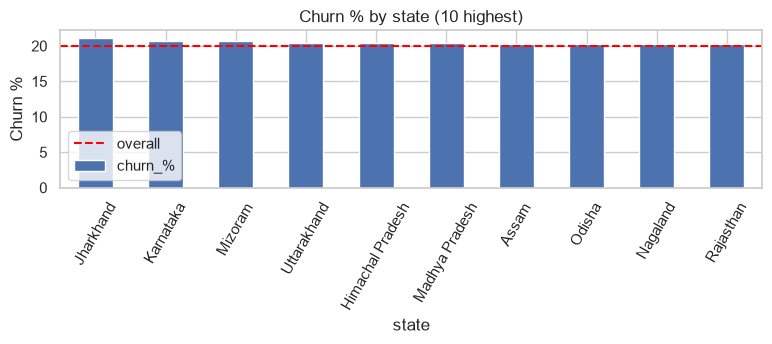

,churn_%,customers
state,,
Jharkhand,21.12,8755
Karnataka,20.71,8845
Mizoram,20.65,8689
Uttarakhand,20.42,8856
Himachal Pradesh,20.41,8682
Madhya Pradesh,20.38,8817
Assam,20.30,8547
Odisha,20.25,8712
Nagaland,20.23,8562


In [18]:
display(churn_by(df["state"], "Churn % by state (10 highest)", rotate=60, top=10))

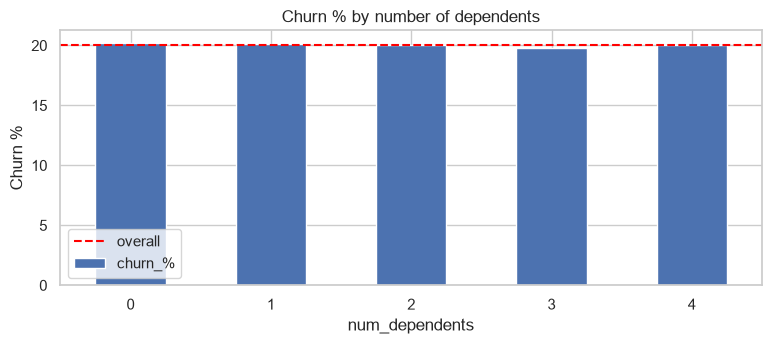

,churn_%,customers
num_dependents,,
0,20.23,48927
1,20.15,48701
2,20.00,48605
3,19.81,48694
4,20.05,48626


In [19]:
display(churn_by(df["num_dependents"], "Churn % by number of dependents"))

In [ ]:
6.2 numeric features(grouped into bands)


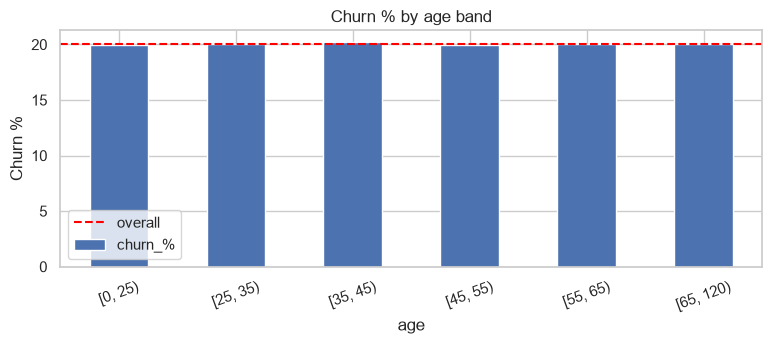

,churn_%,customers
age,,
"[0, 25)",19.99,29874
"[25, 35)",20.00,42255
"[35, 45)",20.25,42710
"[45, 55)",19.91,42818
"[55, 65)",20.03,42951
"[65, 120)",20.08,42945


In [20]:
age_band = pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120], right=False)
display(churn_by(age_band, "Churn % by age band", rotate=20))

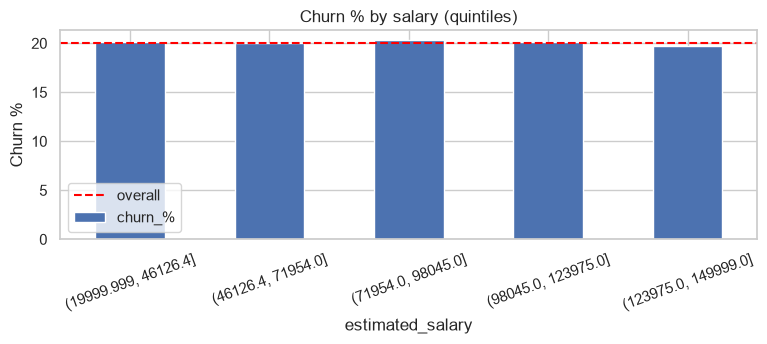

,churn_%,customers
estimated_salary,,
"(19999.999, 46126.4]",20.16,48711
"(46126.4, 71954.0]",20.04,48713
"(71954.0, 98045.0]",20.29,48709
"(98045.0, 123975.0]",20.08,48710
"(123975.0, 149999.0]",19.68,48710


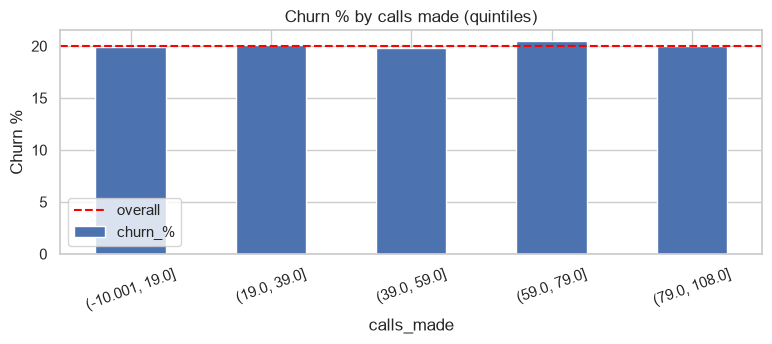

,churn_%,customers
calls_made,,
"(-10.001, 19.0]",19.87,50034
"(19.0, 39.0]",20.10,48433
"(39.0, 59.0]",19.77,48644
"(59.0, 79.0]",20.48,48859
"(79.0, 108.0]",20.03,47583


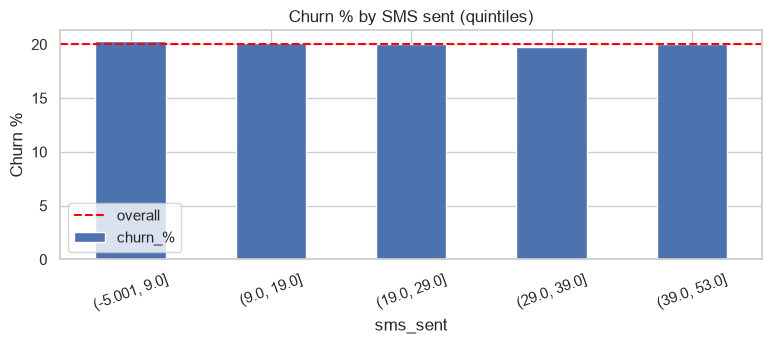

,churn_%,customers
sms_sent,,
"(-5.001, 9.0]",20.27,51410
"(9.0, 19.0]",20.10,49075
"(19.0, 29.0]",20.03,48313
"(29.0, 39.0]",19.76,48481
"(39.0, 53.0]",20.06,46274


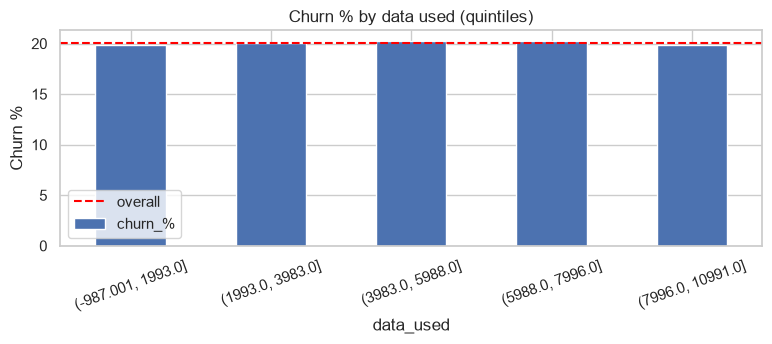

,churn_%,customers
data_used,,
"(-987.001, 1993.0]",19.82,48721
"(1993.0, 3983.0]",20.06,48717
"(3983.0, 5988.0]",20.24,48697
"(5988.0, 7996.0]",20.28,48726
"(7996.0, 10991.0]",19.85,48692


In [21]:
for col, title in [("estimated_salary", "salary"), ("calls_made", "calls made"),
                   ("sms_sent", "SMS sent"), ("data_used", "data used")]:
    band = pd.qcut(df[col], 5, duplicates="drop")
    display(churn_by(band, f"Churn % by {title} (quintiles)", rotate=20))

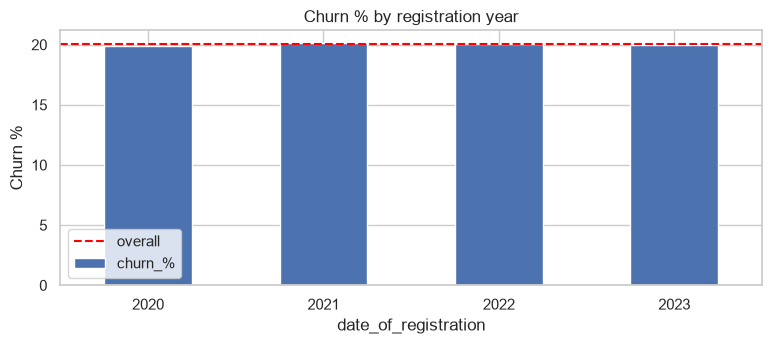

,churn_%,customers
date_of_registration,,
2020,19.91,73126
2021,20.17,72926
2022,20.08,72926
2023,20.01,24575


In [22]:
reg_year = df["date_of_registration"].dt.year
display(churn_by(reg_year, "Churn % by registration year"))

In [ ]:
6.3 distributions and correlations

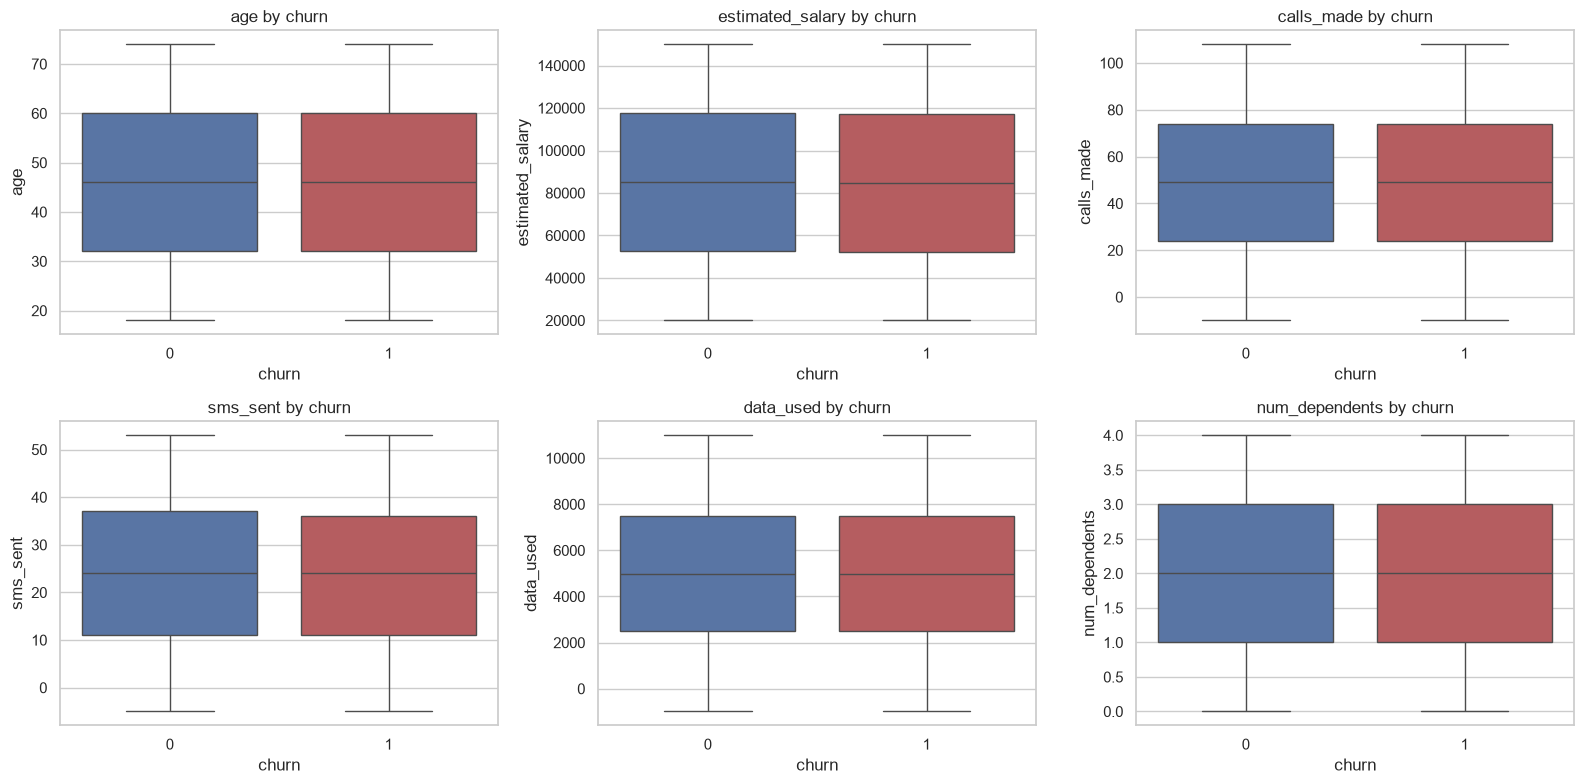

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["age", "estimated_salary", "calls_made",
                                  "sms_sent", "data_used", "num_dependents"]):
    sns.boxplot(data=df, x="churn", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(f"{col} by churn")
plt.tight_layout(); plt.show()

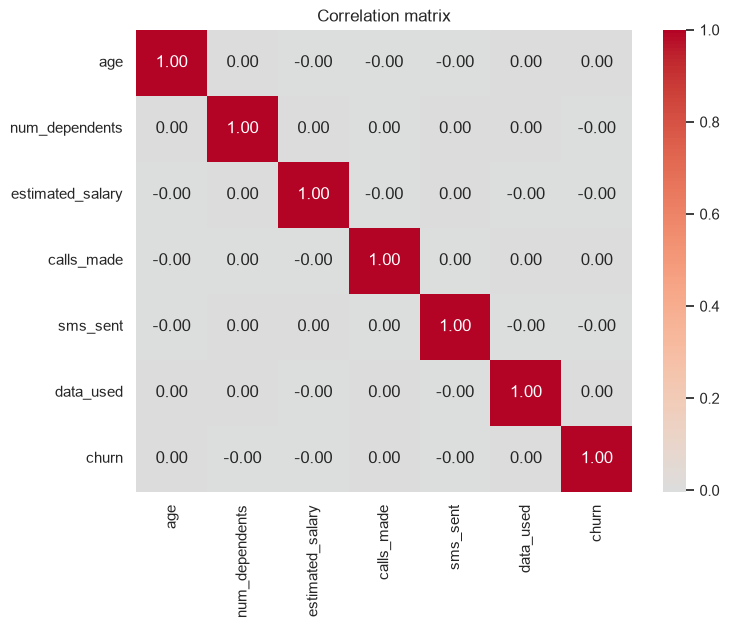

In [24]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[["age", "num_dependents", "estimated_salary", "calls_made",
                "sms_sent", "data_used", "churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [ ]:
7.feature engineering

In [25]:
customer_ids = df["customer_id"].copy()
ref_date = df["date_of_registration"].max()

data = df.copy()
data["tenure_days"] = (ref_date - data["date_of_registration"]).dt.days
data["reg_year"] = data["date_of_registration"].dt.year
data["reg_month"] = data["date_of_registration"].dt.month
data["total_activity"] = data["calls_made"] + data["sms_sent"]
data["data_per_activity"] = data["data_used"] / data["total_activity"].replace(0, np.nan)
data["data_per_activity"] = data["data_per_activity"].fillna(0)
data["salary_per_dependent"] = data["estimated_salary"] / (data["num_dependents"] + 1)

data = data.drop(columns=["customer_id", "pincode", "date_of_registration"])
print(data.shape)
data.head()

(243553, 17)


,telecom_partner,gender,age,state,city,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,tenure_days,reg_year,reg_month,total_activity,data_per_activity,salary_per_dependent
0,Reliance Jio,F,25,Karnataka,Kolkata,4,124962,44,45,-361,0,1219,2020,1,89,-4.056180,24992.400000
1,Reliance Jio,F,55,Mizoram,Mumbai,2,130556,62,39,5973,0,1219,2020,1,101,59.138614,43518.666667
2,Vodafone,F,57,Arunachal Pradesh,Delhi,0,148828,49,24,193,1,1219,2020,1,73,2.643836,148828.000000
3,BSNL,M,46,Tamil Nadu,Kolkata,1,38722,80,25,9377,1,1219,2020,1,105,89.304762,19361.000000
4,BSNL,F,26,Tripura,Delhi,2,55098,78,15,1393,0,1219,2020,1,93,14.978495,18366.000000


In [ ]:
8.train and test split

In [26]:
X = data.drop(columns="churn")
y = data["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"churn {y_train.mean():.2%}")
print("Test :", X_test.shape, f"churn {y_test.mean():.2%}")

cat_cols = ["telecom_partner", "gender", "state", "city"]
num_features = [c for c in X.columns if c not in cat_cols]
print("Numeric features   :", num_features)
print("Categorical features:", cat_cols)

def make_preprocessor(scale=True):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=500, sparse_output=False))]), cat_cols),
    ])

# smaller stratified sample used for the slow steps (comparison + tuning)
if len(X_train) > SAMPLE_N:
    X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=SAMPLE_N,
                                      stratify=y_train, random_state=RANDOM_STATE)
else:
    X_s, y_s = X_train, y_train
print("Rows used for model comparison / tuning:", len(X_s))

Train: (194842, 16) churn 20.05%
Test : (48711, 16) churn 20.05%
Numeric features   : ['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'tenure_days', 'reg_year', 'reg_month', 'total_activity', 'data_per_activity', 'salary_per_dependent']
Categorical features: ['telecom_partner', 'gender', 'state', 'city']
Rows used for model comparison / tuning: 60000


In [ ]:
9.model comparision

In [27]:
models = {
    "Dummy (baseline)": Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("clf", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([
        ("prep", make_preprocessor(scale=True)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("clf", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                       class_weight="balanced", n_jobs=-1,
                                       random_state=RANDOM_STATE))]),
    "Hist Gradient Boosting": Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced", max_iter=150,
                                               random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "recall": "recall",
           "precision": "precision", "f1": "f1", "accuracy": "accuracy"}

rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_s, y_s, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"Model": name, **{m: res[f"test_{m}"].mean() for m in scoring}})
    print("done:", name)

comparison = pd.DataFrame(rows).set_index("Model").sort_values("roc_auc", ascending=False)
display(comparison.round(4))

done: Dummy (baseline)
done: Logistic Regression
done: Random Forest
done: Hist Gradient Boosting


,roc_auc,recall,precision,f1,accuracy
Model,,,,,
Hist Gradient Boosting,0.5067,0.5083,0.2037,0.2908,0.5032
Random Forest,0.5048,0.3414,0.2051,0.2562,0.6026
Logistic Regression,0.5020,0.4995,0.2023,0.2879,0.5048
Dummy (baseline),0.5000,0.0000,0.0000,0.0000,0.7995


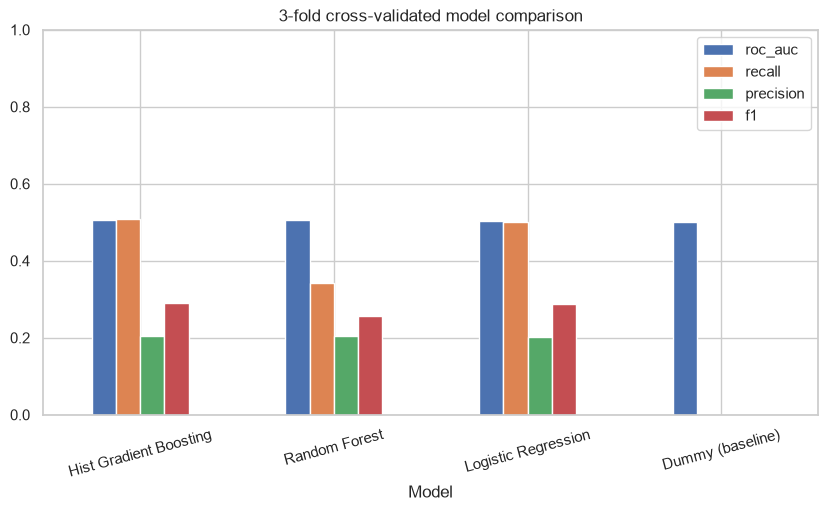

Best model by ROC-AUC: Hist Gradient Boosting


In [28]:
ax = comparison[["roc_auc", "recall", "precision", "f1"]].plot(kind="bar", figsize=(10, 5), rot=15)
ax.set_title(f"{N_FOLDS}-fold cross-validated model comparison")
ax.set_ylim(0, 1)
plt.show()

candidates = comparison.drop(index="Dummy (baseline)")
best_name = candidates.index[0]
print("Best model by ROC-AUC:", best_name)

In [ ]:
10.hyper-parameter tuning of the best model

In [31]:
param_spaces = {
    "Logistic Regression": {"clf__C": np.logspace(-3, 2, 20)},
    "Random Forest": {
        "clf__n_estimators": [150, 250],
        "clf__max_depth": [6, 10, 14],
        "clf__min_samples_leaf": [10, 20, 50],
        "clf__max_features": ["sqrt", 0.3]},
    "Hist Gradient Boosting": {
        "clf__learning_rate": [0.03, 0.05, 0.1],
        "clf__max_depth": [None, 3, 5],
        "clf__max_leaf_nodes": [15, 31],
        "clf__min_samples_leaf": [20, 50, 100],
        "clf__l2_regularization": [0.0, 1.0, 5.0]},
}

search = RandomizedSearchCV(models[best_name], param_spaces[best_name], n_iter=N_ITER,
                            scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_s, y_s)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)
best_pipe = search.best_estimator_

Best CV ROC-AUC: 0.5043
Best parameters: {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 31, 'clf__max_depth': None, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 1.0}


In [ ]:
11.choose the decision threshold

Chosen threshold: 0.504  -> flags 29.1% of training customers


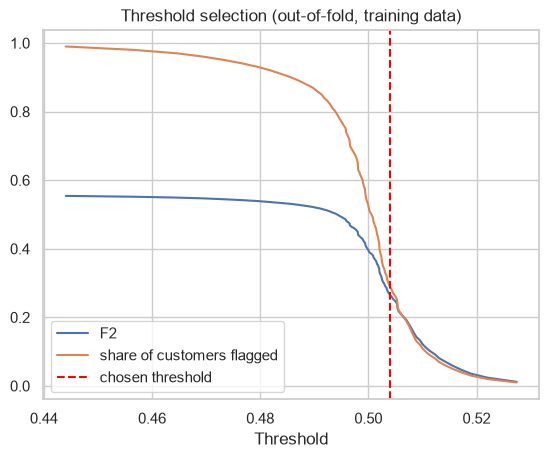

In [32]:
oof_train = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=1)[:, 1]

grid = np.unique(np.quantile(oof_train, np.linspace(0.01, 0.99, 99)))
rows = []
for t in grid:
    flagged = oof_train >= t
    rows.append({"threshold": t, "flag_rate": flagged.mean(),
                 "fbeta": fbeta_score(y_train, flagged, beta=BETA)})
thr_table = pd.DataFrame(rows)

allowed = thr_table[thr_table["flag_rate"] <= MAX_FLAG_RATE]
if allowed.empty:
    THRESHOLD = float(np.quantile(oof_train, 1 - MAX_FLAG_RATE))
else:
    THRESHOLD = float(allowed.loc[allowed["fbeta"].idxmax(), "threshold"])

print(f"Chosen threshold: {THRESHOLD:.3f}  -> flags {(oof_train >= THRESHOLD).mean():.1%} of training customers")

plt.plot(thr_table["threshold"], thr_table["fbeta"], label=f"F{BETA}")
plt.plot(thr_table["threshold"], thr_table["flag_rate"], label="share of customers flagged")
plt.axvline(THRESHOLD, color="red", ls="--", label="chosen threshold")
plt.xlabel("Threshold"); plt.legend(); plt.title("Threshold selection (out-of-fold, training data)")
plt.show()

12.final evaluation on the held-out test set

In [33]:
best_pipe.fit(X_train, y_train)
test_proba = best_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

print(f"ROC-AUC            : {roc_auc_score(y_test, test_proba):.4f}")
print(f"PR-AUC (avg prec.) : {average_precision_score(y_test, test_proba):.4f}   (baseline = churn rate {y_test.mean():.4f})")
print(f"Accuracy           : {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision          : {precision_score(y_test, test_pred, zero_division=0):.4f}")
print(f"Recall             : {recall_score(y_test, test_pred):.4f}")
print(f"F1                 : {f1_score(y_test, test_pred):.4f}")
print(f"Share flagged      : {test_pred.mean():.1%}")
print()
print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"], zero_division=0))

ROC-AUC            : 0.4990
PR-AUC (avg prec.) : 0.2008   (baseline = churn rate 0.2005)
Accuracy           : 0.6369
Precision          : 0.1980
Recall             : 0.2661
F1                 : 0.2271
Share flagged      : 26.9%

              precision    recall  f1-score   support

      Stayed       0.80      0.73      0.76     38946
     Churned       0.20      0.27      0.23      9765

    accuracy                           0.64     48711
   macro avg       0.50      0.50      0.49     48711
weighted avg       0.68      0.64      0.66     48711



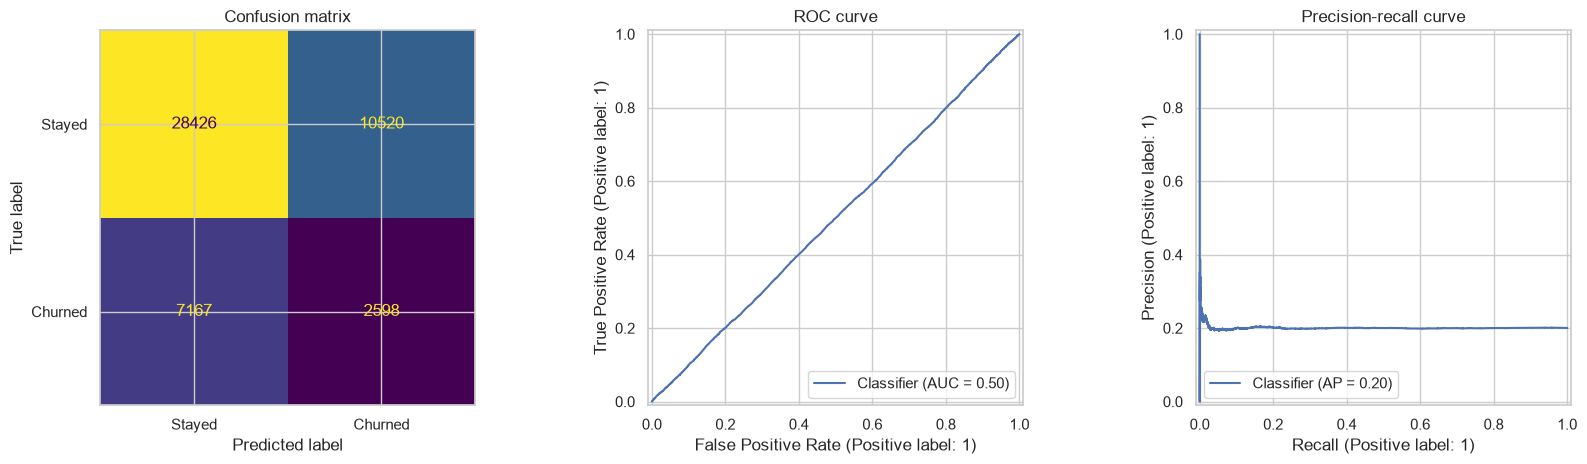

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["Stayed", "Churned"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[1])
axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[2])
axes[2].set_title("Precision-recall curve")
plt.tight_layout(); plt.show()

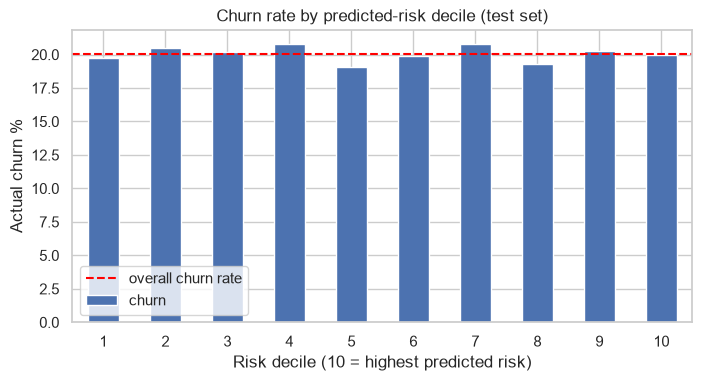

Top-decile lift: 1.00x the average churn rate


In [35]:
lift_df = pd.DataFrame({"proba": test_proba, "churn": y_test.values})
lift_df["decile"] = pd.qcut(lift_df["proba"].rank(method="first"), 10, labels=range(1, 11))
lift = lift_df.groupby("decile", observed=True)["churn"].mean() * 100
ax = lift.plot(kind="bar", color="#4C72B0", figsize=(8, 3.8), rot=0)
ax.axhline(y_test.mean() * 100, color="red", ls="--", label="overall churn rate")
ax.set_xlabel("Risk decile (10 = highest predicted risk)"); ax.set_ylabel("Actual churn %")
ax.set_title("Churn rate by predicted-risk decile (test set)"); ax.legend()
plt.show()
print(f"Top-decile lift: {lift.iloc[-1] / (y_test.mean() * 100):.2f}x the average churn rate")

In [ ]:
13.goal1-which variables drive churn

,feature,importance,std
13,total_activity,0.00343,0.00184
12,reg_month,0.00300,0.00067
15,salary_per_dependent,0.00247,0.00276
1,gender,0.00181,0.00028
11,reg_year,0.00000,0.00000
8,sms_sent,-0.00029,0.00095
0,telecom_partner,-0.00050,0.00089
5,num_dependents,-0.00056,0.00108
9,data_used,-0.00123,0.00080
6,estimated_salary,-0.00157,0.00316


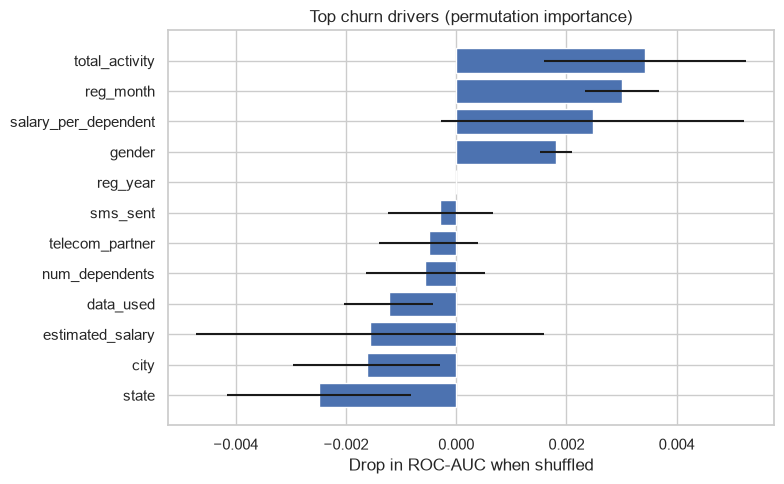

In [36]:
n_perm = min(20000, len(X_test))
X_perm = X_test.sample(n_perm, random_state=RANDOM_STATE)
y_perm = y_test.loc[X_perm.index]

perm = permutation_importance(best_pipe, X_perm, y_perm, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"feature": X_perm.columns,
                            "importance": perm.importances_mean,
                            "std": perm.importances_std})
                .sort_values("importance", ascending=False))
display(importance.head(10).round(5))

top = importance.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#4C72B0")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Top churn drivers (permutation importance)")
plt.tight_layout(); plt.show()

In [37]:
lr = Pipeline([("prep", make_preprocessor(scale=True)),
               ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
lr.fit(X_train, y_train)

names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
odds = pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef)})
odds.index = odds.index.str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)
odds = odds.sort_values("coef", key=np.abs, ascending=False)
print("odds ratio > 1 -> raises churn risk, < 1 -> lowers it (numeric features: per 1 std-dev increase)")
display(odds.head(12).round(3))

odds ratio > 1 -> raises churn risk, < 1 -> lowers it (numeric features: per 1 std-dev increase)


,coef,odds_ratio
state_West Bengal,-0.051,0.950
state_Jharkhand,0.050,1.051
state_Chhattisgarh,-0.046,0.955
state_Mizoram,0.041,1.042
state_Uttarakhand,0.026,1.027
city_Delhi,-0.026,0.975
state_Karnataka,0.025,1.025
state_Tripura,-0.023,0.977
state_Kerala,-0.023,0.977
state_Rajasthan,0.022,1.022


In [38]:
# Business view: churn rate for key customer segments
seg_frames = []
for label, grouping in [("telecom_partner", df["telecom_partner"]),
                        ("gender", df["gender"]),
                        ("age_band", age_band),
                        ("salary_band", pd.qcut(df["estimated_salary"], 4, duplicates="drop")),
                        ("data_used_band", pd.qcut(df["data_used"], 4, duplicates="drop")),
                        ("tenure_band", pd.qcut(data["tenure_days"], 4, duplicates="drop"))]:
    g = df.groupby(grouping, observed=True)["churn"].agg(["mean", "count"])
    g["mean"] = (g["mean"] * 100).round(2)
    g.index = [f"{label}: {i}" for i in g.index]
    seg_frames.append(g.rename(columns={"mean": "churn_%", "count": "customers"}))
segments = pd.concat(seg_frames)
display(segments)
spread = segments["churn_%"].max() - segments["churn_%"].min()
print(f"Highest segment churn: {segments['churn_%'].idxmax()} ({segments['churn_%'].max()}%)")
print(f"Lowest segment churn : {segments['churn_%'].idxmin()} ({segments['churn_%'].min()}%)")

,churn_%,customers
telecom_partner: Airtel,20.37,60905
telecom_partner: BSNL,19.86,60723
telecom_partner: Reliance Jio,20.02,61123
telecom_partner: Vodafone,19.95,60802
gender: F,20.30,97576
gender: M,19.88,145977
"age_band: [0, 25)",19.99,29874
"age_band: [25, 35)",20.00,42255
"age_band: [35, 45)",20.25,42710
"age_band: [45, 55)",19.91,42818


Highest segment churn: telecom_partner: Airtel (20.37%)
Lowest segment churn : data_used_band: (-987.001, 2490.0] (19.79%)


In [ ]:
14.goal2-churn risk score for every customer

,customers,actual_churn_rate
risk_band,,
Low,121772,19.93
Medium,62594,20.28
High,59187,20.06


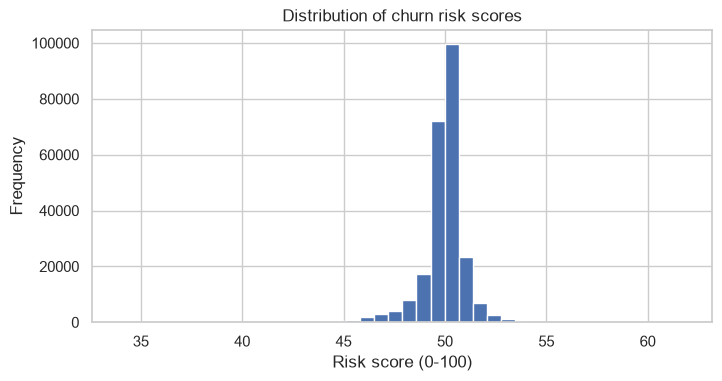

In [39]:
oof_all = cross_val_predict(clone(best_pipe), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                            method="predict_proba", n_jobs=1)[:, 1]
median_score = float(np.median(oof_all))

def band(p):
    if p >= THRESHOLD:
        return "High"
    if p >= median_score:
        return "Medium"
    return "Low"

result = pd.DataFrame({"customer_id": customer_ids.values,
                       "state": df["state"].values,
                       "telecom_partner": df["telecom_partner"].values,
                       "churn_actual": y.values,
                       "churn_risk_score": (oof_all * 100).round(1)})
result["risk_band"] = [band(p) for p in oof_all]

band_check = (result.groupby("risk_band")["churn_actual"]
                    .agg(customers="count", actual_churn_rate="mean")
                    .reindex(["Low", "Medium", "High"]))
band_check["actual_churn_rate"] = (band_check["actual_churn_rate"] * 100).round(2)
display(band_check)

result["churn_risk_score"].plot(kind="hist", bins=40, figsize=(8, 3.8), color="#4C72B0")
plt.title("Distribution of churn risk scores"); plt.xlabel("Risk score (0-100)")
plt.show()

In [ ]:
15.goal3-introduce churn_flag(yes=1/no=0)

In [40]:
result["churn_flag"] = (oof_all >= THRESHOLD).astype(int)

print(result["churn_flag"].value_counts().rename({0: "NO (0)", 1: "YES (1)"}))
print("\nFlag vs actual churn:")
print(pd.crosstab(result["churn_flag"], result["churn_actual"],
                  rownames=["CHURN_FLAG"], colnames=["Actual churn"]))

flag_churn = result.loc[result["churn_flag"] == 1, "churn_actual"].mean() * 100
other_churn = result.loc[result["churn_flag"] == 0, "churn_actual"].mean() * 100
print(f"\nChurn rate among flagged customers : {flag_churn:.1f}%")
print(f"Churn rate among non-flagged        : {other_churn:.1f}%")
print(f"Recall (share of all churners flagged): {result.loc[result['churn_actual'] == 1, 'churn_flag'].mean():.1%}")

customers_scored = df_raw.loc[df.index].copy()
customers_scored["churn_risk_score"] = result["churn_risk_score"].values
customers_scored["risk_band"] = result["risk_band"].values
customers_scored["CHURN_FLAG"] = result["churn_flag"].values

campaign = (result[result["churn_flag"] == 1]
            .sort_values("churn_risk_score", ascending=False)
            [["customer_id", "state", "telecom_partner", "churn_risk_score", "risk_band", "churn_flag"]])

customers_scored.to_csv("customers_with_churn_flag.csv", index=False)
campaign.to_csv("retention_campaign_list.csv", index=False)
print(f"\nSaved customers_with_churn_flag.csv ({len(customers_scored):,} rows)")
print(f"Saved retention_campaign_list.csv ({len(campaign):,} customers to target)")
campaign.head(10)

churn_flag
NO (0)     184366
YES (1)     59187
Name: count, dtype: int64

Flag vs actual churn:
Actual churn       0      1
CHURN_FLAG                 
0             147409  36957
1              47317  11870

Churn rate among flagged customers : 20.1%
Churn rate among non-flagged        : 20.0%
Recall (share of all churners flagged): 24.3%

Saved customers_with_churn_flag.csv (243,553 rows)
Saved retention_campaign_list.csv (59,187 customers to target)


,customer_id,state,telecom_partner,churn_risk_score,risk_band,churn_flag
50612,50613,West Bengal,BSNL,61.8,High,1
233997,233998,Bihar,Reliance Jio,58.7,High,1
240288,240289,Maharashtra,BSNL,58.5,High,1
149780,149781,Madhya Pradesh,Airtel,58.4,High,1
184917,184918,Madhya Pradesh,Airtel,58.4,High,1
111085,111086,Chhattisgarh,BSNL,58.1,High,1
69360,69361,Jharkhand,Reliance Jio,58.1,High,1
213952,213953,Jharkhand,Vodafone,57.7,High,1
99227,99228,Jharkhand,Reliance Jio,57.6,High,1
96944,96945,Jharkhand,Airtel,57.4,High,1


In [ ]:
conclusion:We built a churn model for No-churn telecom that addresses all three goals:the drivers of churn are identified and explained ,every customer
 has  a 0-100 churn risk score witha low/medium/high band,and the new churn_flag gives marketing a ready to use campaign list.
     